In [1]:
import numpy as np
import pandas as pa 
import matplotlib.pyplot as plt
import seaborn as se 
from sklearn.model_selection import train_test_split 
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.utils.class_weight import compute_class_weight
from sklearn.preprocessing import PolynomialFeatures
from tensorflow.keras.models import Sequential , load_model
from tensorflow.keras.layers import Dense , Normalization
from tensorflow.keras.callbacks import EarlyStopping
from imblearn.over_sampling import RandomOverSampler
import keras as ks
import tensorflow as tf
%matplotlib inline

In [2]:
file = pa.read_csv('diabetes_prediction_dataset.csv')
file.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [3]:
file.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,41.885856,0.07485,0.039420,27.320767,5.527507,138.058060,0.085000
std,22.516840,0.26315,0.194593,6.636783,1.070672,40.708136,0.278883
min,0.080000,0.00000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,24.000000,0.00000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,43.000000,0.00000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,60.000000,0.00000,0.000000,29.580000,6.200000,159.000000,0.000000
max,80.000000,1.00000,1.000000,95.690000,9.000000,300.000000,1.000000


In [4]:
file.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  str    
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  str    
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), str(2)
memory usage: 6.9 MB


In [5]:
print(file['gender'].value_counts())
print()
print(file['heart_disease'].value_counts())
print()
print(file['hypertension'].value_counts())
print()
print(file['smoking_history'].value_counts())
print()
print(file['diabetes'].value_counts())


gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64

heart_disease
0    96058
1     3942
Name: count, dtype: int64

hypertension
0    92515
1     7485
Name: count, dtype: int64

smoking_history
No Info        35816
never          35095
former          9352
current         9286
not current     6447
ever            4004
Name: count, dtype: int64

diabetes
0    91500
1     8500
Name: count, dtype: int64


In [6]:
x_file_gender = [0 if i == 'Female' else 1 if i == 'Male' else 2 for i in file['gender']]
x_file_age = [0 if j < 18 else 1 if j >= 18 and j < 30 else 2 if j >= 30 and j < 40 else 3 if j >= 40 and j < 50 else 4 if j >= 50 and j < 60 else 5 if j >= 60 and j < 70 else 6 for j in file['age']]
x_file_bmi = [0 if t < 10 else 1 if t >= 10 and t < 20 else 2 if t >= 20 and t < 30 else 3 if t >= 30 and t < 40 else 4 if t >= 40 and t < 50 else 5 if t >= 50 and t < 60 else 6 for t in file['bmi']]
x_file_smoking_history = [0 if h == 'never' else 1 if h == 'No Info' else 2 if h == 'not current' else 3 if h == 'former' else 4 if h == 'ever' else 5 for h in file['smoking_history']]
x_file_HbA1c_level = [0 if n < 3.5 else 1 if n >= 3.5 and n < 4.5 else 2 if n >= 4.5 and n < 5 else 3 if n >= 5 and n < 6.5 else 4 if n >= 6.5 and n < 7 else 5 if n >= 7 and n < 8.5 else 6 for n in file['HbA1c_level']]
x_file_blood_glucose_level = [0 if a < 80 else 1 if a >= 80 and a < 95 else 2 if a >= 95 and a < 100 else 3 if a >= 100 and a < 150 else 4 if a >= 150 and a < 200 else 5 if a >= 200 and a < 250 else 6 for a in file['blood_glucose_level']]


In [7]:
print(x_file_gender[:10])
print()
print(x_file_age[:10])
print()
print(x_file_bmi[:10])
print()
print(x_file_smoking_history[:10])
print()
print(x_file_blood_glucose_level[:10])
print()
print(x_file_HbA1c_level[:10])

[0, 0, 1, 0, 1, 0, 0, 0, 1, 0]

[6, 4, 1, 2, 6, 1, 3, 6, 3, 2]

[2, 2, 2, 2, 2, 2, 1, 2, 3, 2]

[0, 1, 0, 5, 5, 0, 0, 1, 0, 0]

[3, 1, 4, 4, 4, 1, 5, 1, 3, 3]

[4, 4, 3, 3, 2, 4, 4, 3, 2, 3]


In [8]:
file['x_file_gender'] = x_file_gender
file['x_file_age'] = x_file_age
file['x_file_bmi'] = x_file_bmi
file['x_file_smoking_history'] = x_file_smoking_history
file['x_file_blood_glucose_level'] = x_file_blood_glucose_level
file['x_file_HbA1c_level'] = x_file_HbA1c_level

In [9]:
file.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes,x_file_gender,x_file_age,x_file_bmi,x_file_smoking_history,x_file_blood_glucose_level,x_file_HbA1c_level
0,Female,80.0,0,1,never,25.19,6.6,140,0,0,6,2,0,3,4
1,Female,54.0,0,0,No Info,27.32,6.6,80,0,0,4,2,1,1,4
2,Male,28.0,0,0,never,27.32,5.7,158,0,1,1,2,0,4,3
3,Female,36.0,0,0,current,23.45,5.0,155,0,0,2,2,5,4,3
4,Male,76.0,1,1,current,20.14,4.8,155,0,1,6,2,5,4,2


In [10]:
file = file.drop(['age','bmi','gender','smoking_history','HbA1c_level','blood_glucose_level'],axis=1)
file.head()

,hypertension,heart_disease,diabetes,x_file_gender,x_file_age,x_file_bmi,x_file_smoking_history,x_file_blood_glucose_level,x_file_HbA1c_level
0,0,1,0,0,6,2,0,3,4
1,0,0,0,0,4,2,1,1,4
2,0,0,0,1,1,2,0,4,3
3,0,0,0,0,2,2,5,4,3
4,1,1,0,1,6,2,5,4,2


<Axes: >

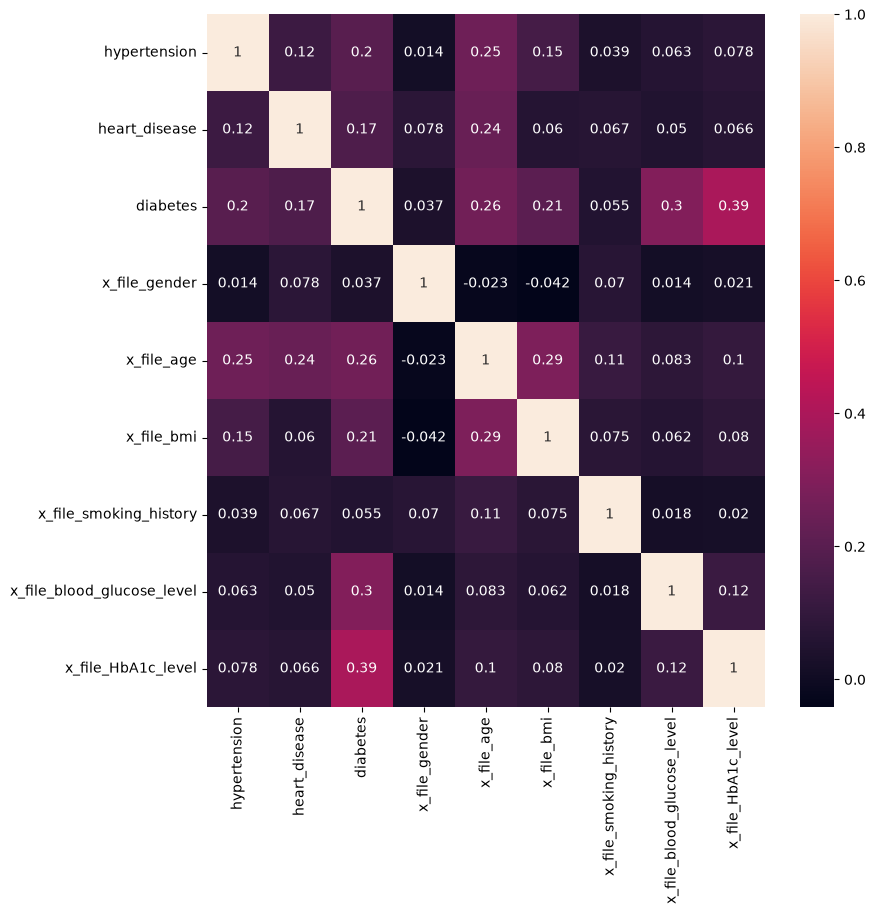

In [11]:
plt.figure(figsize=(9,9))
se.heatmap(file.corr(),annot=True)

In [12]:
x = file.drop('diabetes',axis=1)
y = file['diabetes']

X_train , X_test , Y_train , Y_test = train_test_split(x,y,test_size=0.2,random_state=42)

print(X_train.shape)
print(X_test.shape)
print()
print(Y_train.shape)
print(Y_test.shape)

(80000, 8)
(20000, 8)

(80000,)
(20000,)


In [13]:
X_train

,hypertension,heart_disease,x_file_gender,x_file_age,x_file_bmi,x_file_smoking_history,x_file_blood_glucose_level,x_file_HbA1c_level
75220,0,0,1,6,2,3,1,1
48955,0,0,1,6,2,0,3,3
44966,0,0,0,2,2,4,4,1
13568,0,0,0,1,1,2,3,3
92727,1,0,0,5,2,5,1,2
...,...,...,...,...,...,...,...,...
6265,0,0,1,3,3,0,1,3
54886,0,0,0,0,2,0,4,3
76820,0,0,1,3,2,0,1,3
860,0,0,0,2,2,0,4,3


In [14]:
X_test

,hypertension,heart_disease,x_file_gender,x_file_age,x_file_bmi,x_file_smoking_history,x_file_blood_glucose_level,x_file_HbA1c_level
75721,0,0,0,0,2,1,3,3
80184,0,0,0,0,2,1,3,3
19864,0,0,1,5,2,3,5,1
76699,0,0,0,0,1,0,3,3
92991,0,0,0,2,4,2,5,3
...,...,...,...,...,...,...,...,...
32595,0,0,0,3,2,2,4,3
29313,1,0,1,5,4,3,1,1
37862,0,0,0,3,2,0,3,2
53421,0,1,1,6,2,1,3,4


In [15]:
Y_train

75220    0
48955    1
44966    0
13568    0
92727    0
        ..
6265     0
54886    0
76820    0
860      0
15795    0
Name: diabetes, Length: 80000, dtype: int64

In [16]:
Y_test

75721    0
80184    0
19864    0
76699    0
92991    1
        ..
32595    0
29313    0
37862    0
53421    0
42410    0
Name: diabetes, Length: 20000, dtype: int64

In [ ]:
# class_weights = compute_class_weight('balanced',classes=np.unique(Y_train),y=Y_train)
# class_weights_dict = dict(enumerate(class_weights))
# print(class_weights_dict)

# ros = RandomOverSampler(
#   sampling_strategy=0.35,
#   random_state=42
# )
# X_train , Y_train = ros.fit_resample(X_train,Y_train)

In [18]:
model_log = LogisticRegression()
model_tree = DecisionTreeClassifier()
model_random = RandomForestClassifier()
model_knn = KNeighborsClassifier()
 

In [19]:
model_log.fit(X_train,Y_train)
model_random.fit(X_train,Y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [20]:
out_log = model_log.predict(X_test)
out_random = model_random.predict(X_test)

In [21]:
print(model_log.score(X_test,Y_test))
print(model_random.score(X_test,Y_test))

0.9516
0.95755


In [22]:
print(out_log[:10])
print()
print(out_random[:10])
print()
print(Y_test[:10])

[0 0 0 0 0 1 0 0 0 0]

[0 0 0 0 0 0 0 0 0 0]

75721    0
80184    0
19864    0
76699    0
92991    1
76434    0
84004    0
80917    0
60767    0
50074    0
Name: diabetes, dtype: int64


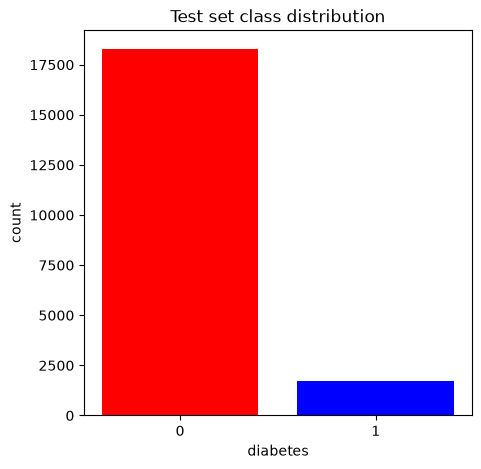

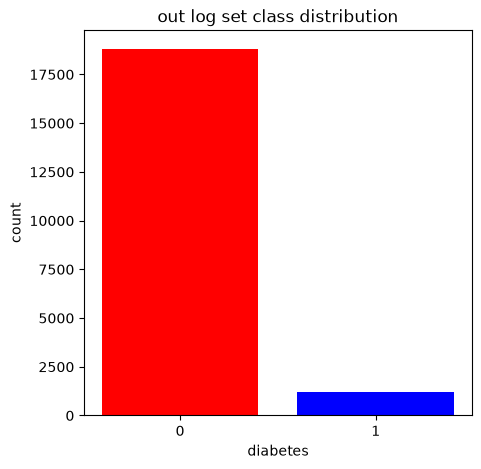

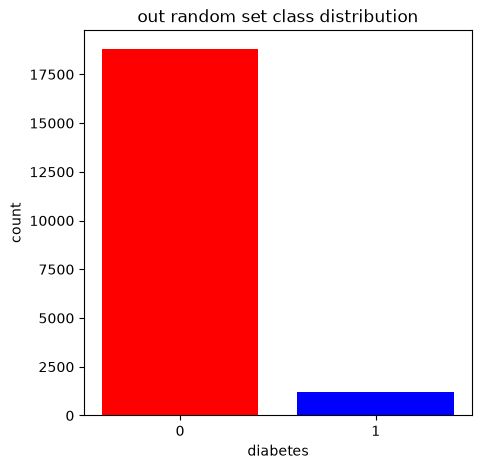

diabetes counts:
 diabetes
0    18292
1     1708
Name: count, dtype: int64

diabetes counts predict robot log:
 0    18814
1     1186
Name: count, dtype: int64

diabetes counts predict robot random:
 0    18809
1     1191
Name: count, dtype: int64


In [23]:
counts = Y_test.value_counts().sort_index()
out_counts_log = pa.Series(out_log).value_counts().sort_index()
out_counts_random = pa.Series(out_random).value_counts().sort_index()

plt.close()
plt.figure(figsize=(5, 5))
plt.bar(counts.index.astype(str), counts.values, color=['red', 'blue'])
plt.xlabel('diabetes')
plt.ylabel('count')
plt.title('Test set class distribution')


plt.figure(figsize=(5, 5))
plt.bar(out_counts_log.index.astype(str), out_counts_log.values, color=['red', 'blue'])
plt.xlabel('diabetes')
plt.ylabel('count')
plt.title('out log set class distribution')

plt.figure(figsize=(5, 5))
plt.bar(out_counts_random.index.astype(str), out_counts_random.values, color=['red', 'blue'])
plt.xlabel('diabetes')
plt.ylabel('count')
plt.title('out random set class distribution')

plt.show()
print("diabetes counts:\n", counts)
print()
print('diabetes counts predict robot log:\n',out_counts_log)
print()
print('diabetes counts predict robot random:\n',out_counts_random)

In [24]:
erly = EarlyStopping(monitor='val_loss',mode='min',patience=5,restore_best_weights=True)

In [25]:
model_deep = Sequential()
model_deep.add(Dense(128,activation='relu',input_dim=8))
model_deep.add(Dense(64,activation='relu'))
model_deep.add(Dense(32,activation='relu'))
model_deep.add(Dense(2,activation='sigmoid'))
model_deep.compile(loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),optimizer='adam',metrics=['accuracy'])
model_deep.summary()


d:\python==3.12.4\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,554 (45.13 KB)

 Trainable params: 11,554 (45.13 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
model_deep.fit(X_train,Y_train,epochs=1000,callbacks=[erly],batch_size=16,validation_data=(X_test,Y_test))

Epoch 1/1000


d:\python==3.12.4\Lib\site-packages\keras\src\backend\tensorflow\nn.py:1402: UserWarning: "`sparse_categorical_crossentropy` received `from_logits=True`, but the `output` argument was produced by a Softmax activation and thus does not represent logits. Was this intended?
  output, from_logits = _get_logits(


4997/5000 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9485 - loss: 0.1467

d:\python==3.12.4\Lib\site-packages\keras\src\backend\tensorflow\nn.py:1402: UserWarning: "`sparse_categorical_crossentropy` received `from_logits=True`, but the `output` argument was produced by a Softmax activation and thus does not represent logits. Was this intended?
  output, from_logits = _get_logits(


5000/5000 ━━━━━━━━━━━━━━━━━━━━ 21s 4ms/step - accuracy: 0.9485 - loss: 0.1467 - val_accuracy: 0.9477 - val_loss: 0.1348
Epoch 2/1000
5000/5000 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - accuracy: 0.9592 - loss: 0.1151 - val_accuracy: 0.9593 - val_loss: 0.1114
Epoch 3/1000
5000/5000 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step - accuracy: 0.9599 - loss: 0.1124 - val_accuracy: 0.9593 - val_loss: 0.1126
Epoch 4/1000
5000/5000 ━━━━━━━━━━━━━━━━━━━━ 10s 1ms/step - accuracy: 0.9604 - loss: 0.1115 - val_accuracy: 0.9598 - val_loss: 0.1137
Epoch 5/1000
5000/5000 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step - accuracy: 0.9610 - loss: 0.1105 - val_accuracy: 0.9603 - val_loss: 0.1115
Epoch 6/1000
5000/5000 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step - accuracy: 0.9607 - loss: 0.1107 - val_accuracy: 0.9599 - val_loss: 0.1102
Epoch 7/1000
5000/5000 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step - accuracy: 0.9613 - loss: 0.1097 - val_accuracy: 0.9603 - val_loss: 0.1093
Epoch 8/1000
5000/5000 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step - accuracy: 0.9604 - loss: 0.11

In [27]:
out_deep = model_deep.predict(X_test)

625/625 ━━━━━━━━━━━━━━━━━━━━ 0s 611us/step


In [28]:
los , acc = model_deep.evaluate(X_test,Y_test)
print(acc)

 48/625 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9564 - loss: 0.1068    

d:\python==3.12.4\Lib\site-packages\keras\src\backend\tensorflow\nn.py:1402: UserWarning: "`sparse_categorical_crossentropy` received `from_logits=True`, but the `output` argument was produced by a Softmax activation and thus does not represent logits. Was this intended?
  output, from_logits = _get_logits(


625/625 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9602 - loss: 0.1090
0.9601500034332275


In [29]:
print(out_deep[:10])
print(out_deep[:10][4])
print(max(out_deep[:10][4]))
print()
print(Y_test[:10])

[[9.3454778e-01 6.3265994e-02]
 [9.3454778e-01 6.3265994e-02]
 [1.0000000e+00 4.4653604e-29]
 [9.4437182e-01 4.8841227e-02]
 [6.8127954e-01 3.8371575e-01]
 [5.2212262e-01 5.2275670e-01]
 [8.2788765e-01 2.0532978e-01]
 [9.9986190e-01 2.2328518e-04]
 [8.9237285e-01 1.3949867e-01]
 [9.9999672e-01 9.1204138e-06]]
[0.68127954 0.38371575]
0.68127954

75721    0
80184    0
19864    0
76699    0
92991    1
76434    0
84004    0
80917    0
60767    0
50074    0
Name: diabetes, dtype: int64


In [30]:
out_array_deep = out_deep.tolist()
array = []
for i in out_array_deep :
    array.append(i.index(max(i)))

In [31]:
array[:50]

[0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0]

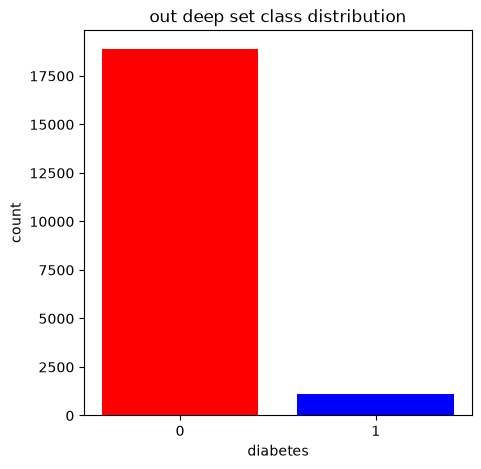

diabetes counts out predict robot deep:
 0    18897
1     1103
Name: count, dtype: int64


In [32]:
out_counts_deep = pa.Series(array).value_counts().sort_index()

plt.figure(figsize=(5, 5))
plt.bar(out_counts_deep.index.astype(str), out_counts_deep.values, color=['red', 'blue'])
plt.xlabel('diabetes')
plt.ylabel('count')
plt.title('out deep set class distribution')

plt.show()
print('diabetes counts out predict robot deep:\n',out_counts_deep)

In [33]:
model_deep.save('diabetes_kaggle.h5')

In [34]:
#import joblib

#joblib.dump(model_random, "diabetes_random.pkl")